# Inverse Fourier-Feature Physics-Informed Neural Network for the Lorenz System

This notebook builds an **Inverse Fourier-Feature Physics-Informed Neural Network (Inverse FPINN)** for the Lorenz system. Its goal is to learn the system parameters and approximate the state trajectoriesasan keadaan $x(t)$, $y(t)$, dan $z(t)$ sekaligus mengestimasi parameter fisik $\sigma$, $\rho$, dan $\beta$ dari data observasi yang tersedia.

Unlike conventional supervised approaches, FPINN does not rely solely on data fitting. The differential equations of the Lorenz system are also incorporated into the objective function through the physics residual, so that the learned solution is expected to remain consistent with the system's dynamics.

The experimental workflow in this notebook is as follows:

1. defining the Lorenz system and its reference parameters;
2. generating synthetic data using `solve_ivp`;
3. normalizing time and splitting the data into training and test observations;
4. adding noise to the training observations;
5. constructing collocation points for the physics loss;
6. building an FPINN with Fourier Features, gated residual blocks, and a trainable global skip;
7. defining the data loss, initial-condition loss, and physics loss;
8. performing two-stage training using AdamW followed by L-BFGS;
9. evaluating parameter estimates, trajectory predictions, gates, physics residuals, and the Lorenz attractor.

With the current configuration, `TRAIN_FRACTION = 0.5`, meaning that 50% of the 1,000 data points are randomly selected as training observations.

## 1. Persamaan Sistem Lorenz

The Lorenz system is a three-dimensional nonlinear dynamical system described by:

$$
\frac{dx}{dt}=\sigma(y-x),
$$

$$
\frac{dy}{dt}=x(\rho-z)-y,
$$

$$
\frac{dz}{dt}=xy-\beta z.
$$

The variables $x(t)$, $y(t)$, and $z(t)$ are the system states, while $\sigma$, $\rho$, and $\beta$ are parameters that govern the Lorenz dynamics.

In the **forward problem**, the physical parameters are assumed to be known and the equations are used to obtain the trajectory. In this notebook's **inverse problem**, the parameters $\sigma$, $\rho$, and $\beta$ are trainable. The model must learn all three alongside approximations of $x(t)$, $y(t)$, and $z(t)$.

Because the Lorenz system is chaotic, small differences in parameters or states can lead to different trajectories over a sufficiently long time. Therefore, evaluation should not rely on trajectory error alone; parameter estimates and physics residual magnitudes should also be examined.

## 2. Library Imports and Reproducibility

This section imports the libraries used for numerical computation, visualization, ODE solving, and building the FPINN with PyTorch.

`SEED = 42` is applied to `random`, NumPy, dan PyTorch to make processes involving random numbers easier to reproduce. Jika CUDA tersedia, seed juga is applied to GPU.

The compute device is selected automatically:

- `cuda` if a GPU is available;
- `cpu` if a GPU is unavailable.

Setting random seeds helps reproducibility, although small numerical variations may still occur on GPUs due to certain operation implementations.

In [25]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import solve_ivp
sns.set_theme(style="darkgrid")

import torch
import torch.nn as nn
import torch.optim as optim

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 3. Experiment Configuration

This section configures the experiment's main hyperparameters.

The reference parameters of the Lorenz system are:

$$
\sigma_{true}=10,\qquad
\rho_{true}=28,\qquad
\beta_{true}=\frac{8}{3}.
$$

These values are used only to generate synthetic data and as reference values during evaluation. The model is not initialized with the reference values. The initial guesses are $\sigma=7$, $\rho=22$, dan $\beta=2$.

The simulation domain is $t\in[0,50]$ with 1,000 data points. 50% of the points are selected as training observations.

The total loss combines three components:

$$
\mathcal{L}
=
w_d\mathcal{L}_{data}
+w_p\mathcal{L}_{physics}
+w_{IC}\mathcal{L}_{IC}.
$$

Pada konfigurasi ini:

$$
w_d=8,\qquad w_p=1,\qquad w_{IC}=5.
$$

These weights determine the relative contribution of each constraint during optimization. They can be tuned if one loss component becomes too dominant.

In [26]:
# Lorenz ground truth
SIGMA_TRUE = 10.0
RHO_TRUE = 28.0
BETA_TRUE = 8.0 / 3.0
X0, Y0, Z0 = 1.0, 1.0, 1.0

# Domain data
T_MAX = 50.0
N_DATA = 1000
TRAIN_FRACTION = 0.5

# Collocation
N_COLLOCATION_POOL = 5000
ADAMW_COLLOCATION_BATCH = 1024
LBFGS_COLLOCATION = 2000

# Architecture
HIDDEN = 256
NUM_BLOCKS = 8

# Initial guesses for inverse parameters
SIGMA_INIT = 7.0
RHO_INIT = 22.0
BETA_INIT = 2.0

# Manual loss weights
W_DATA = 5.0
W_PHYS = 1.0
W_IC = 5

# Optimizers
ADAMW_EPOCHS = 5000
ADAMW_LR = 1e-3
ADAMW_WEIGHT_DECAY = 1e-6
LBFGS_MAX_ITER = 700
# LOG_EVERY = 50

NOISE_LEVEL = 0.1

print(f"Training observations: {TRAIN_FRACTION:.0%} of {N_DATA} points")

Training observations: 50% of 1000 points


## 4. Generating Reference Data with `solve_ivp`

Before training the FPINN, a reference trajectory is needed as synthetic data. The `lorenz_rhs` function defines the right-hand side of the Lorenz system, and `solve_ivp` then solves the initial-value problem over the interval $t\in[0,50]$.

The initial condition is:

$$
(x_0,y_0,z_0)=(1,1,1).
$$

The `DOP853` solver is used with strict numerical tolerances (`rtol=1e-10` and `atol=1e-12`) so that the reference solution has small integration error relative to the model error being analyzed.

The solver outputs are stored as `X_true`, `Y_true`, and `Z_true`. These data serve as **ground truth** for constructing training observations and for final evaluation.

In [27]:
def lorenz_rhs(t, state, sigma, rho, beta):
    x, y, z = state
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z
    return [dx, dy, dz]

time = np.linspace(0.0, T_MAX, N_DATA)
solution = solve_ivp(
    lorenz_rhs,
    (0.0, T_MAX),
    [X0, Y0, Z0],
    args=(SIGMA_TRUE, RHO_TRUE, BETA_TRUE),
    t_eval=time,
    method="DOP853",
    rtol=1e-10,
    atol=1e-12,
)

if not solution.success:
    raise RuntimeError(solution.message)

X_true, Y_true, Z_true = solution.y
print("Data points generated:", len(time))

Data points generated: 1000


### 4.1 Visualizing the Reference Data

All three states are plotted over time to inspect the trajectory characteristics before training.

This visualization helps verify successful numerical integration and inspect the scale of each state. The Lorenz system produces nonlinear oscillations that are not simply periodic, so the patterns of $x(t)$, $y(t)$, dan $z(t)$ dapat berubah secara kompleks sepanjang interval simulasi.

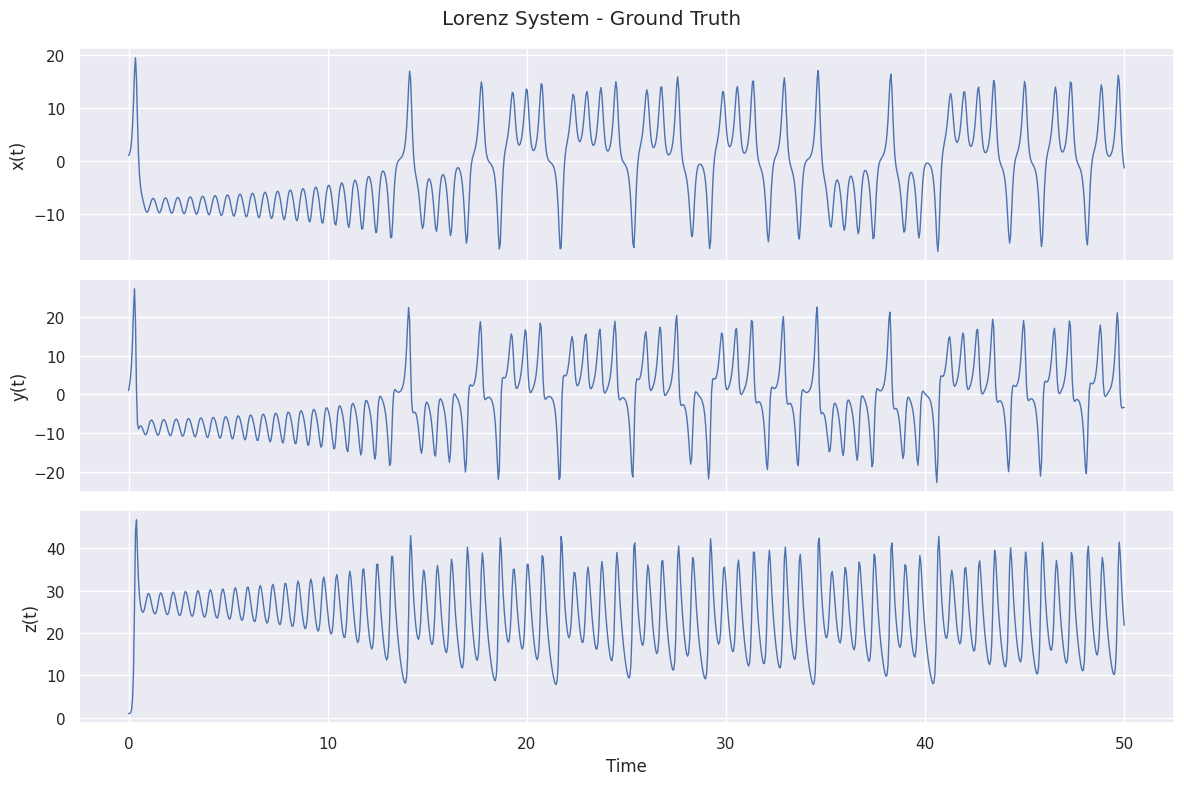

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, values, label in zip(axes, [X_true, Y_true, Z_true], ["x(t)", "y(t)", "z(t)"]):
    ax.plot(time, values, linewidth=1.0)
    ax.set_ylabel(label)
    ax.grid(True)
axes[-1].set_xlabel("Time")
fig.suptitle("Lorenz System - Ground Truth")
plt.tight_layout()
plt.show()

## 5. Preprocessing, Random Observation Split, Noise, and Collocation Points

Time input is normalized as follows:

$$
\tau=\frac{t}{T_{max}},
$$

so that $\tau\in[0,1]$. This normalization keeps the neural network's input range well controlled.

Because the model differentiates with respect to $\tau$, the chain rule must be taken into account. Given $\tau=t/T_{max}$ berlaku:

$$
\frac{d\tau}{dt}=\frac{1}{T_{max}},
$$

sehingga:

$$
\frac{dx}{dt}
=
\frac{dx}{d\tau}\frac{d\tau}{dt}
=
\frac{1}{T_{max}}\frac{dx}{d\tau}.
$$

The same relationship applies to $y$ and $z$. The factor $1/T_{max}$ is then applied in the physics residual.

### Random Observation Split

Dengan `TRAIN_FRACTION = 0.5`, **50%** of all points are randomly selected without replacement for training. The unselected points are retained as the test set.

### Noise in the Training Data

Observasi training diberi Gaussian noise dengan tingkat:

$$
\text{NOISE\_LEVEL}=0.05.
$$

For each state, the noise amplitude is scaled by that state's standard deviation. In general, the form is:

$$
\tilde{x}=x+0.1\,s_x\,\varepsilon,
\qquad
\varepsilon\sim\mathcal{N}(0,1).
$$

The same implementation is used for $y$ and $z$.

### Collocation points

Sebanyak 5000 collocation points dibentuk secara merata pada $\tau\in[0,1]$. Titik ini tidak membutuhkan label ground truth karena digunakan untuk mengevaluasi apakah output network memenuhi persamaan diferensial.

### `state_scale`

`state_scale` dihitung dari standard deviation setiap kolom state training noisy:

$$
\mathbf{s}=(s_x,s_y,s_z).
$$

Nilai ini digunakan untuk menormalisasi data loss, initial-condition loss, dan physics loss agar perbedaan skala antar-state tidak membuat satu state mendominasi fungsi objektif.

In [29]:
t_norm_np = (time / T_MAX).astype(np.float32)

all_idx = np.arange(N_DATA)
n_train = int(TRAIN_FRACTION * N_DATA)
train_idx = np.sort(np.random.choice(all_idx, size=n_train, replace=False))
test_idx = np.setdiff1d(all_idx, train_idx)

def to_tensor(a):
    return torch.tensor(a, dtype=torch.float32, device=device).view(-1, 1)

t_all = to_tensor(t_norm_np)
X_all = to_tensor(X_true)
Y_all = to_tensor(Y_true)
Z_all = to_tensor(Z_true)

t_train = t_all[train_idx]
X_train = X_all[train_idx]
Y_train = Y_all[train_idx]
Z_train = Z_all[train_idx]

t_test = t_all[test_idx]
X_test = X_all[test_idx]
Y_test = Y_all[test_idx]
Z_test = Z_all[test_idx]


X_train_noisy = X_train + NOISE_LEVEL * torch.std(X_train) * torch.randn_like(X_train)
Y_train_noisy = Y_train + NOISE_LEVEL * torch.std(Y_train) * torch.randn_like(Y_train)
Z_train_noisy = Z_train + NOISE_LEVEL * torch.std(Z_train) * torch.randn_like(Z_train)

t0 = to_tensor([0.0])
state0 = torch.tensor([[X0, Y0, Z0]], dtype=torch.float32, device=device)

t_collocation_pool = torch.linspace(
    0.0, 1.0, N_COLLOCATION_POOL, device=device
).view(-1, 1)

state_scale = torch.std(
    torch.cat([X_train_noisy, Y_train_noisy, Z_train_noisy], dim=1),
    dim=0,
    unbiased=False
).clamp_min(1e-6)

print("Train points:", len(train_idx))
print("Test points :", len(test_idx))
print("State scale :", state_scale.detach().cpu().numpy())

Train points: 500
Test points : 500
State scale : [7.9655204 8.920857  8.195876 ]


### 5.1 Locations of Training Observation Points

The following plot shows the ground truth and the points selected as training observations.

Because the training indices are selected randomly, the observation points are distributed across the time interval. This plot uses the ground-truth values at the training indices to show the sampling locations; the noise used during training was added in the preceding preprocessing stage.

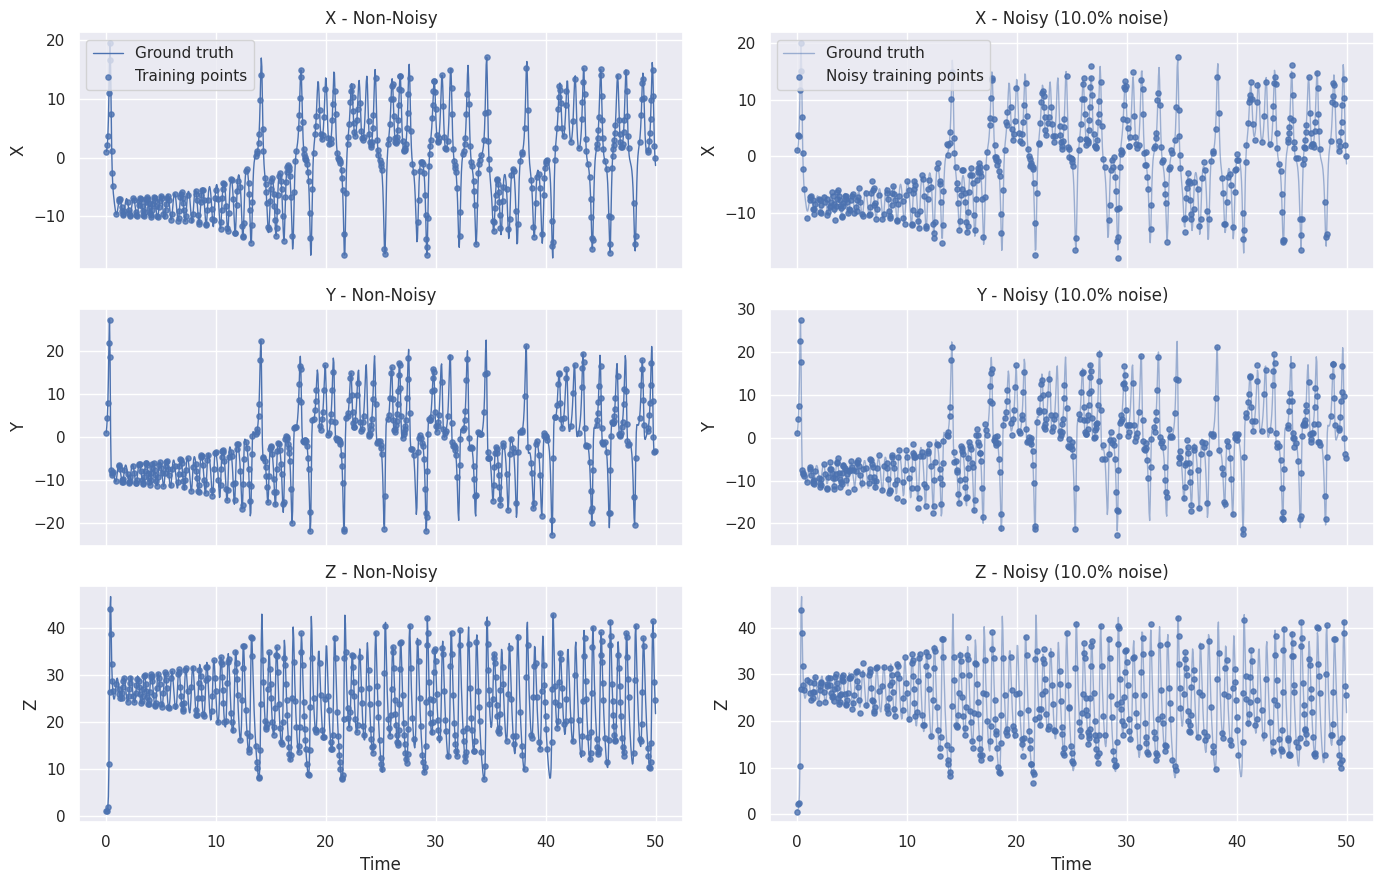

In [30]:
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)

states = [
    (X_true, X_train_noisy, "X"),
    (Y_true, Y_train_noisy, "Y"),
    (Z_true, Z_train_noisy, "Z"),
]

for i, (truth, noisy, label) in enumerate(states):
    # Non-noisy
    axes[i, 0].plot(
        time, truth,
        linewidth=1.0,
        label="Ground truth"
    )
    axes[i, 0].scatter(
        time[train_idx],
        truth[train_idx],
        s=14,
        alpha=0.8,
        label="Training points"
    )
    axes[i, 0].set_ylabel(label)
    axes[i, 0].set_title(f"{label} - Non-Noisy")
    axes[i, 0].grid(True)

    # Noisy
    axes[i, 1].plot(
        time, truth,
        linewidth=1.0,
        alpha=0.5,
        label="Ground truth"
    )
    axes[i, 1].scatter(
        time[train_idx],
        noisy.detach().cpu().numpy().ravel(),
        s=14,
        alpha=0.8,
        label="Noisy training points"
    )
    axes[i, 1].set_ylabel(label)
    axes[i, 1].set_title(f"{label} - Noisy ({NOISE_LEVEL * 100:.1f}% noise)")
    axes[i, 1].grid(True)

axes[0, 0].legend()
axes[0, 1].legend()

axes[2, 0].set_xlabel("Time")
axes[2, 1].set_xlabel("Time")

plt.tight_layout()
plt.show()

## 6. Fourier Features and Gated Residual Block

The architecture uses two components before the final output: **Fourier Features** for time encoding and a **Gated Residual Block** for transforming the hidden representation.

### 6.1 Fourier Features

Input $\tau$ dipetakan menjadi kombinasi nilai asli, sinus, dan cosinus:

$$
\phi(\tau)=
\left[
\tau,
\sin(2\pi f_1\tau),\ldots,\sin(2\pi f_m\tau),
\cos(2\pi f_1\tau),\ldots,\cos(2\pi f_m\tau)
\right].
$$

With `n_freq=20`, the input dimension after encoding is:

$$
1+2(20)=41.
$$

This representation provides the network with a multi-frequency basis, making temporal variations easier to represent than using a single scalar time input.

### 6.2 Gated Residual Block

For a hidden input $\mathbf{x}$, residual branch dihitung sebagai:

$$
\mathbf{h}
=
W_2\tanh(W_1\mathbf{x}+b_1)+b_2.
$$

The block output is then:

$$
\mathbf{x}_{out}
=
\operatorname{LayerNorm}(\mathbf{x}+\mathbf{g}\odot\mathbf{h}),
$$

where $\mathbf{g}$ is a trainable gate for each hidden feature.

Gate dibatasi pada interval $[g_{min},g_{max}]=[0.1,0.9]$:

$$
\rho_g
=
B\tanh\left(\frac{\ell}{B}\right),
$$

$$
\mathbf{g}
=
g_{min}+(g_{max}-g_{min})\sigma(\rho_g),
$$

dengan $B=\texttt{logit\_bound}=3$ dan $\ell$ adalah trainable gate logit.

Pembatasan ini mencegah gate mencapai 0 atau 1 secara penuh. `tanh` pada logit juga membatasi input sigmoid agar tidak bergerak tanpa batas ke daerah saturasi.

In [31]:
class GatedResBlock(nn.Module):
    def __init__(self, hidden, gate_min=0.1, gate_max=0.9, logit_bound=3.0):
        super().__init__()
        self.fc1 = nn.Linear(hidden, hidden)
        self.fc2 = nn.Linear(hidden, hidden)
        self.norm = nn.LayerNorm(hidden)

        self.gate_logit = nn.Parameter(torch.zeros(hidden))

        self.gate_min = gate_min
        self.gate_max = gate_max
        self.logit_bound = logit_bound

    def gate(self):
        rho = self.logit_bound * torch.tanh(self.gate_logit / self.logit_bound)
        return self.gate_min + (self.gate_max - self.gate_min) * torch.sigmoid(rho)

    def forward(self, x):
        residual = x

        h = torch.tanh(self.fc1(x))
        h = self.fc2(h)

        g = self.gate()

        return self.norm(residual + g * h)

class FourierFeatures(nn.Module):
    def __init__(self, n_freq=16, max_freq=16.0):
        super().__init__()
        self.register_buffer("freqs", torch.linspace(1.0, max_freq, n_freq))

    def forward(self, t):
        w = 2 * torch.pi * t * self.freqs
        return torch.cat([t, torch.sin(w), torch.cos(w)], dim=-1)

## 7. FPINN Architecture

The overall architecture can be summarized as:

$$
\tau
\rightarrow
\text{Fourier Features}
\rightarrow
\text{Input Layer}
\rightarrow
\text{4 Gated Residual Blocks}
\rightarrow
\text{Global Skip}
\rightarrow
\text{LayerNorm}
\rightarrow
[x,y,z].
$$

### 7.1 Input Layer

Fourier encoding with 20 frequencies produces 41 features. These features are projected to a hidden dimension of 128 through a linear layer and `Tanh` activation.

### 7.2 Residual Backbone

The hidden representation passes through four `GatedResBlock` modules. Each block contains two linear layers, `Tanh`, a trainable gate, a residual connection, and `LayerNorm`.

### 7.3 Trainable Global Skip

The initial representation after the input layer, $\mathbf{x}_{in}$, disimpan dan ditambahkan kembali setelah seluruh residual block:

$$
\mathbf{x}_{global}
=
\mathbf{x}_{res}+\lambda\mathbf{x}_{in}.
$$

The value of $\lambda$ is trainable but constrained to the interval:

$$
0.05\leq\lambda\leq0.5.
$$

Its initial value is $\lambda=0.3$.

### 7.4 Output Layer

After the global skip, the hidden representation passes through `LayerNorm` and a final linear layer that produces three outputs:

$$
\hat{x}(\tau),\quad \hat{y}(\tau),\quad \hat{z}(\tau).
$$

Output state tidak diberi aktivasi pembatas sehingga dapat bernilai positif maupun negatif.

### 7.5 Parameter fisik trainable

Parameter Lorenz dioptimasi dalam domain log:

$$
\sigma=e^{\theta_\sigma},\qquad
\rho=e^{\theta_\rho},\qquad
\beta=e^{\theta_\beta}.
$$

Transformasi eksponensial memastikan ketiga parameter tetap positif selama training.

Dua code cell berikut menampilkan ringkasan arsitektur dengan `torchinfo`. Cell kedua juga menghitung total parameter dan jumlah parameter trainable secara eksplisit.

In [32]:
class FPINN(nn.Module):
    def __init__(
        self,
        hidden=128,
        num_blocks=4,
        sigma0=7.0,
        rho0=22.0,
        beta0=2.0,
        global_skip_min=0.05,
        global_skip_max=0.5,
        global_skip_init=0.3,
        n_freq=20,
        max_freq=20,
    ):
        super().__init__()
        self.fourier = FourierFeatures(n_freq=n_freq, max_freq=max_freq)
        self.input_layer = nn.Sequential(
            nn.Linear(1 + (n_freq * 2), hidden),
            nn.Tanh()
        )
        self.res_blocks = nn.ModuleList([
            GatedResBlock(hidden=hidden) for _ in range(num_blocks)
        ])
        self.final_norm = nn.LayerNorm(hidden)
        self.output_layer = nn.Linear(hidden, 3)

        self.log_sigma = nn.Parameter(torch.log(torch.tensor(float(sigma0))))
        self.log_rho = nn.Parameter(torch.log(torch.tensor(float(rho0))))
        self.log_beta = nn.Parameter(torch.log(torch.tensor(float(beta0))))

        self.global_skip_min = global_skip_min
        self.global_skip_max = global_skip_max
        p = (global_skip_init - global_skip_min) / (global_skip_max - global_skip_min)
        p = min(max(p, 1e-6), 1.0 - 1e-6)
        self.raw_global_lambda = nn.Parameter(torch.tensor(math.log(p / (1.0 - p)), dtype=torch.float32))
        self.initialize_weights()

    def initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.xavier_normal_(module.weight, gain=nn.init.calculate_gain("tanh"))
                nn.init.zeros_(module.bias)

    def get_global_lambda(self):
        return self.global_skip_min + (
            self.global_skip_max - self.global_skip_min
        ) * torch.sigmoid(self.raw_global_lambda)

    def get_parameters_physical(self):
        return torch.exp(self.log_sigma), torch.exp(self.log_rho), torch.exp(self.log_beta)

    def forward(self, t):
        t_feat = self.fourier(t)
        x_input = self.input_layer(t_feat)
        
        x = x_input
        for block in self.res_blocks:
            x = block(x)
        x = x + self.get_global_lambda() * x_input
        x = self.final_norm(x)
        out = self.output_layer(x)
        sigma, rho, beta = self.get_parameters_physical()
        return out[:, 0:1], out[:, 1:2], out[:, 2:3], sigma, rho, beta

model = FPINN(
    hidden=HIDDEN,
    num_blocks=NUM_BLOCKS,
    sigma0=SIGMA_INIT,
    rho0=RHO_INIT,
    beta0=BETA_INIT,
).to(device)

sigma0, rho0, beta0 = model.get_parameters_physical()
print("Initial sigma, rho, beta:", sigma0.item(), rho0.item(), beta0.item())
print("Initial global lambda:", model.get_global_lambda().item())

Initial sigma, rho, beta: 7.0 22.000001907348633 2.0
Initial global lambda: 0.30000001192092896


In [33]:
from torchinfo import summary

summary(
    model,
    input_size=(1, 1),
    device=device,
    col_names=("input_size", "output_size", "num_params", "trainable"),
    verbose=1
)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Trainable
FPINN                                    [1, 1]                    [1, 1]                    4                         True
├─FourierFeatures: 1-1                   [1, 1]                    [1, 41]                   --                        --
├─Sequential: 1-2                        [1, 41]                   [1, 256]                  --                        True
│    └─Linear: 2-1                       [1, 41]                   [1, 256]                  10,752                    True
│    └─Tanh: 2-2                         [1, 256]                  [1, 256]                  --                        --
├─ModuleList: 1-3                        --                        --                        --                        True
│    └─GatedResBlock: 2-3                [1, 256]                  [1, 256]                  256                       True
│    │ 

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Trainable
FPINN                                    [1, 1]                    [1, 1]                    4                         True
├─FourierFeatures: 1-1                   [1, 1]                    [1, 41]                   --                        --
├─Sequential: 1-2                        [1, 41]                   [1, 256]                  --                        True
│    └─Linear: 2-1                       [1, 41]                   [1, 256]                  10,752                    True
│    └─Tanh: 2-2                         [1, 256]                  [1, 256]                  --                        --
├─ModuleList: 1-3                        --                        --                        --                        True
│    └─GatedResBlock: 2-3                [1, 256]                  [1, 256]                  256                       True
│    │ 

## 8. Loss Function

Training uses three loss components: **data loss**, **initial-condition loss**, and **physics loss**. All three are normalized using `state_scale` to balance the contributions from $x$, $y$, and $z$.

### 8.1 Data Loss

The predicted states at the observation points are written as:

$$
\hat{\mathbf{u}}=
[\hat{x},\hat{y},\hat{z}],
$$

while the noisy targets are:

$$
\mathbf{u}=[x,y,z].
$$

With the scale vector $\mathbf{s}=[s_x,s_y,s_z]$, data loss yang digunakan adalah:

$$
\mathcal{L}_{data}
=
\operatorname{mean}
\left[
\left(
\frac{\hat{\mathbf{u}}-\mathbf{u}}{\mathbf{s}}
\right)^2
\right].
$$

### 8.2 Initial-Condition Loss

The model is also constrained to approach the known initial condition:

$$
\mathbf{u}(0)=(1,1,1).
$$

The loss is:

$$
\mathcal{L}_{IC}
=
\operatorname{mean}
\left[
\left(
\frac{\hat{\mathbf{u}}(0)-\mathbf{u}_0}{\mathbf{s}}
\right)^2
\right].
$$

### 8.3 Physics Loss

The physics residual is constructed directly from the Lorenz system:

$$
f_x
=
\frac{d\hat{x}}{dt}-\sigma(\hat{y}-\hat{x}),
$$

$$
f_y
=
\frac{d\hat{y}}{dt}-\left[\hat{x}(\rho-\hat{z})-\hat{y}\right],
$$

$$
f_z
=
\frac{d\hat{z}}{dt}-\left(\hat{x}\hat{y}-\beta\hat{z}\right).
$$

Autograd computes turunan terhadap normalized time $\tau$. Karena $\tau=t/T_{max}$, kode mengubahnya ke turunan terhadap waktu fisik menggunakan:

$$
\frac{d\hat{x}}{dt}
=
\frac{1}{T_{max}}\frac{d\hat{x}}{d\tau},
$$

serta hubungan yang sama untuk $\hat{y}$ dan $\hat{z}$.

Residual digabung menjadi:

$$
\mathbf{f}=[f_x,f_y,f_z],
$$

kemudian dinormalisasi dengan `state_scale`:

$$
\mathcal{L}_{physics}
=
\operatorname{mean}
\left[
\left(
\frac{\mathbf{f}}{\mathbf{s}}
\right)^2
\right].
$$

Loss total adalah:

$$
\mathcal{L}
=
8\mathcal{L}_{data}
+\mathcal{L}_{physics}
+5\mathcal{L}_{IC}.
$$

In [34]:
def predict_states(model, t):
    Xp, Yp, Zp, _, _, _ = model(t)
    return torch.cat([Xp, Yp, Zp], dim=1)

def data_loss(model, t, X, Y, Z, scale):
    pred = predict_states(model, t)
    target = torch.cat([X, Y, Z], dim=1)
    return torch.mean(((pred - target) / scale) ** 2)

def initial_condition_loss(model, t0, state0, scale):
    pred0 = predict_states(model, t0)
    return torch.mean(((pred0 - state0) / scale) ** 2)

def physics_residuals(model, t_norm):
    t = t_norm.detach().clone().requires_grad_(True)
    Xp, Yp, Zp, sigma, rho, beta = model(t)

    dX_dtau = torch.autograd.grad(Xp, t, torch.ones_like(Xp), create_graph=True)[0]
    dY_dtau = torch.autograd.grad(Yp, t, torch.ones_like(Yp), create_graph=True)[0]
    dZ_dtau = torch.autograd.grad(Zp, t, torch.ones_like(Zp), create_graph=True)[0]

    dX_dt = dX_dtau / T_MAX
    dY_dt = dY_dtau / T_MAX
    dZ_dt = dZ_dtau / T_MAX

    f_X = dX_dt - sigma * (Yp - Xp)
    f_Y = dY_dt - (Xp * (rho - Zp) - Yp)
    f_Z = dZ_dt - (Xp * Yp - beta * Zp)
    return f_X, f_Y, f_Z

def physics_loss(model, t_norm, scale):
    f_X, f_Y, f_Z = physics_residuals(model, t_norm)
    residual = torch.cat([f_X, f_Y, f_Z], dim=1)
    return torch.mean((residual / scale) ** 2)

def total_loss(model, t_obs, X_obs, Y_obs, Z_obs, t_phys):
    l_data = data_loss(model, t_obs, X_obs, Y_obs, Z_obs, state_scale)
    l_phys = physics_loss(model, t_phys, state_scale)
    l_ic = initial_condition_loss(model, t0, state0, state_scale)
    total = W_DATA * l_data + W_PHYS * l_phys + W_IC * l_ic
    return total, l_data, l_phys, l_ic

### 8.4 Loss and Gradient Smoke Test

Before full training, a **smoke test** is run using 256 randomly selected collocation points.

The purpose is to verify that:

- forward pass runs successfully;
- ketiga komponen loss can be computed;
- total loss produces gradients when `backward()` is called;
- no tensor-structure errors occur before the lengthy optimization begins.

After the test, gradients are reset using `model.zero_grad(set_to_none=True)`.

In [35]:
idx = torch.randperm(N_COLLOCATION_POOL, device=device)[:256]
t_phys_smoke = t_collocation_pool[idx]
model.zero_grad(set_to_none=True)
loss_smoke, ld, lp, lic = total_loss(model, t_train, X_train_noisy, Y_train_noisy, Z_train_noisy, t_phys_smoke)
loss_smoke.backward()
print(f"Total={loss_smoke.item():.4e} | Data={ld.item():.4e} | Physics={lp.item():.4e} | IC={lic.item():.4e}")
model.zero_grad(set_to_none=True)

Total=3.1481e+01 | Data=3.9714e+00 | Physics=1.1482e+01 | IC=2.8509e-02


## 9. Training Diagnostics Helper

During training, several values are periodically recorded to analyze optimization dynamics.

The recorded history includes:

- total loss;
- data loss;
- physics loss;
- initial-condition loss;
- estimasi $\sigma$, $\rho$, dan $\beta$;
- trainable global skip $\lambda$;
- mean gate pada setiap `GatedResBlock`.

The `gate_diagnostics` function computes the mean gate for each residual block at 256 fixed probe points in $\tau\in[0,1]$.

The function also computes the ratio of the residual-branch norm to the block input norm as a local variable named `scale`, but this value is **not returned or stored in the history** in the current code version. Therefore, the following visualization uses only `gate_means`.

In [36]:
@torch.no_grad()
def gate_diagnostics(model, t_probe):
    z = model.fourier(t_probe)
    x = model.input_layer(z)

    gate_means = []
    gate_mins = []
    gate_maxs = []

    blocks = [
        module for module in model.modules()
        if isinstance(module, GatedResBlock)
    ]

    for block in blocks:
        g = block.gate()

        gate_means.append(g.mean().item())
        gate_mins.append(g.min().item())
        gate_maxs.append(g.max().item())

        x = block(x)

    return gate_means, gate_mins, gate_maxs

t_probe = torch.linspace(0.0, 1.0, 256, device=device).view(-1, 1)

history = {
    "step": [], "stage": [],
    "total": [], "data": [], "physics": [], "ic": [],
    "sigma": [], "rho": [], "beta": [], "lambda": [],
    "gate_means": [], "gate_mins": [], "gate_maxs": [],
}

def record_history(step, stage, losses):
    total, l_data, l_phys, l_ic = losses
    sigma, rho, beta = model.get_parameters_physical()
    gate_means, gate_mins, gate_maxs = gate_diagnostics(model, t_probe)

    history["step"].append(step)
    history["stage"].append(stage)
    history["total"].append(float(total.detach()))
    history["data"].append(float(l_data.detach()))
    history["physics"].append(float(l_phys.detach()))
    history["ic"].append(float(l_ic.detach()))
    history["sigma"].append(float(sigma.detach()))
    history["rho"].append(float(rho.detach()))
    history["beta"].append(float(beta.detach()))
    history["lambda"].append(float(model.get_global_lambda().detach()))
    history["gate_means"].append(gate_means)
    history["gate_mins"].append(gate_mins)
    history["gate_maxs"].append(gate_maxs)

## 10. Stage 1 — Training with AdamW

The first stage uses **AdamW** to iteratively explore the parameters using first-order gradients.

At each epoch:

1. sebanyak 1024 collocation points are randomly sampled from a pool containing 5000 titik;
2. the total loss is computed using noisy training data, the initial condition, and the collocation batch;
3. gradients are computed using `backward()`;
4. the global gradient norm is clipped to:

$$
\|\nabla\|\leq 1,
$$

melalui `clip_grad_norm_`;
5. the network parameters, gates, global skip, and physical parameters are updated by AdamW.

Konfigurasi optimizer adalah:

$$
\text{learning rate}=10^{-3},
\qquad
\text{weight decay}=10^{-6}.
$$

Training runs for 5000 epoch.

For the training history, loss is reevaluated on a fixed subset of 512 collocation points distributed across the pool. This makes diagnostic curves more consistent than recording loss directly from the changing collocation mini-batch at each epoch.

In [37]:
optimizer_adamw = optim.AdamW(
    model.parameters(),
    lr=ADAMW_LR,
    weight_decay=ADAMW_WEIGHT_DECAY,
)

for epoch in range(1, ADAMW_EPOCHS + 1):
    model.train()
    idx = torch.randperm(N_COLLOCATION_POOL, device=device)[:ADAMW_COLLOCATION_BATCH]
    t_phys = t_collocation_pool[idx]

    optimizer_adamw.zero_grad(set_to_none=True)
    losses = total_loss(model, t_train, X_train_noisy, Y_train_noisy, Z_train_noisy, t_phys)
    losses[0].backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer_adamw.step()

    if epoch == 1 or epoch % (ADAMW_EPOCHS//50) == 0 or epoch == ADAMW_EPOCHS:
        eval_idx = torch.linspace(0, N_COLLOCATION_POOL - 1, 512, device=device).long()
        eval_losses = total_loss(model, t_train, X_train_noisy, Y_train_noisy, Z_train_noisy, t_collocation_pool[eval_idx])
        record_history(epoch, "AdamW", eval_losses)
        sigma, rho, beta = model.get_parameters_physical()
        print(
            f"AdamW {epoch:5d}/{ADAMW_EPOCHS} | "
            f"L={eval_losses[0].item():.3e} | "
            f"Ld={eval_losses[1].item():.3e} | "
            f"Lp={eval_losses[2].item():.3e} | "
            f"sigma={sigma.item():.4f} rho={rho.item():.4f} beta={beta.item():.4f}"
        )

AdamW     1/5000 | L=4.483e+01 | Ld=3.620e+00 | Lp=2.597e+01 | sigma=6.9930 rho=21.9780 beta=1.9980
AdamW   100/5000 | L=2.421e+00 | Ld=3.458e-01 | Lp=6.875e-01 | sigma=7.1059 rho=23.1054 beta=1.8595
AdamW   200/5000 | L=1.998e+00 | Ld=2.654e-01 | Lp=6.695e-01 | sigma=7.7533 rho=25.2569 beta=1.8543
AdamW   300/5000 | L=1.789e+00 | Ld=2.416e-01 | Lp=5.814e-01 | sigma=8.4462 rho=26.3995 beta=1.9032
AdamW   400/5000 | L=1.655e+00 | Ld=2.336e-01 | Lp=4.849e-01 | sigma=9.1412 rho=26.9353 beta=1.9809
AdamW   500/5000 | L=1.676e+00 | Ld=2.315e-01 | Lp=5.157e-01 | sigma=9.7392 rho=27.1447 beta=2.0547
AdamW   600/5000 | L=1.598e+00 | Ld=2.276e-01 | Lp=4.575e-01 | sigma=10.2636 rho=27.2324 beta=2.1182
AdamW   700/5000 | L=1.652e+00 | Ld=2.239e-01 | Lp=5.261e-01 | sigma=10.7858 rho=27.2241 beta=2.1603
AdamW   800/5000 | L=1.573e+00 | Ld=2.230e-01 | Lp=4.572e-01 | sigma=11.2511 rho=27.2743 beta=2.1942
AdamW   900/5000 | L=1.561e+00 | Ld=2.178e-01 | Lp=4.685e-01 | sigma=11.6136 rho=27.3806 beta=2.2

## 11. Stage 2 — Refinement with L-BFGS

After AdamW, the parameters are refined using **L-BFGS**. This optimizer uses gradient history to construct an approximation of the objective function's curvature.

Unlike the AdamW stage, L-BFGS uses a **fixed collocation subset** of 2,000 points distributed across the pool. This matters because one L-BFGS step may call the closure multiple times. If collocation data changed on each closure call, the optimizer would evaluate a different objective function each time.

The main configuration is:

- `lr=1.0`;
- `max_iter=700`;
- `history_size=100`;
- `line_search_fn="strong_wolfe"`.

The closure performs the following sequence:

$$
\text{zero grad}
\rightarrow
\text{hitung loss}
\rightarrow
\text{backward}
\rightarrow
\text{return total loss}.
$$

Additional history is recorded at selected closure calls to monitor changes in loss and parameters during refinement.

In [38]:
lbfgs_idx = torch.linspace(0, N_COLLOCATION_POOL - 1, LBFGS_COLLOCATION, device=device).long()
t_phys_lbfgs = t_collocation_pool[lbfgs_idx]

optimizer_lbfgs = optim.LBFGS(
    model.parameters(),
    lr=1.0,
    max_iter=LBFGS_MAX_ITER,
    max_eval=int(LBFGS_MAX_ITER * 1.5),
    tolerance_grad=1e-9,
    tolerance_change=1e-12,
    history_size=100,
    line_search_fn="strong_wolfe",
)

lbfgs_calls = 0
base_step = ADAMW_EPOCHS

def closure():
    global lbfgs_calls
    optimizer_lbfgs.zero_grad(set_to_none=True)
    losses = total_loss(model, t_train, X_train_noisy, Y_train_noisy, Z_train_noisy, t_phys_lbfgs)
    losses[0].backward()
    lbfgs_calls += 1
    if lbfgs_calls == 1 or lbfgs_calls % (LBFGS_MAX_ITER//20) == 0:
        record_history(base_step + lbfgs_calls, "L-BFGS", losses)
        sigma, rho, beta = model.get_parameters_physical()
        print(
            f"L-BFGS call {lbfgs_calls:4d} | L={losses[0].item():.3e} | "
            f"sigma={sigma.item():.4f} rho={rho.item():.4f} beta={beta.item():.4f}"
        )
    return losses[0]

model.train()
optimizer_lbfgs.step(closure)

final_losses = total_loss(model, t_train, X_train_noisy, Y_train_noisy, Z_train_noisy, t_phys_lbfgs)
record_history(base_step + lbfgs_calls + 1, "L-BFGS", final_losses)

L-BFGS call    1 | L=1.391e+00 | sigma=15.7497 rho=27.5188 beta=2.2815
L-BFGS call   35 | L=1.256e+00 | sigma=16.4313 rho=27.7508 beta=2.3478
L-BFGS call   70 | L=1.246e+00 | sigma=19.0618 rho=27.8218 beta=2.3405
L-BFGS call  105 | L=1.228e+00 | sigma=19.8699 rho=27.8378 beta=2.3483
L-BFGS call  140 | L=1.174e+00 | sigma=19.7287 rho=27.8403 beta=2.3339
L-BFGS call  175 | L=1.064e+00 | sigma=18.0124 rho=27.7733 beta=2.3463
L-BFGS call  210 | L=9.553e-01 | sigma=16.2802 rho=27.6991 beta=2.3688
L-BFGS call  245 | L=8.630e-01 | sigma=14.0566 rho=27.6759 beta=2.4153
L-BFGS call  280 | L=8.009e-01 | sigma=12.6788 rho=27.7090 beta=2.4424
L-BFGS call  315 | L=7.608e-01 | sigma=11.6662 rho=27.8147 beta=2.4763
L-BFGS call  350 | L=7.290e-01 | sigma=10.9437 rho=27.8742 beta=2.4769
L-BFGS call  385 | L=7.031e-01 | sigma=10.6584 rho=27.8938 beta=2.4759
L-BFGS call  420 | L=6.869e-01 | sigma=10.5317 rho=27.9107 beta=2.4804
L-BFGS call  455 | L=6.758e-01 | sigma=10.5810 rho=27.9282 beta=2.4794
L-BFGS

## 12. Model Evaluation and Parameter Estimation

After both training stages are complete, the model is evaluated at all 1,000 time points.

This section produces:

$$
\hat{x}(t),\qquad \hat{y}(t),\qquad \hat{z}(t),
$$

serta estimasi akhir:

$$
\hat{\sigma},\qquad \hat{\rho},\qquad \hat{\beta}.
$$

For each physical parameter, the relative error is calculated as:

$$
\text{Relative Error}(\%)
=
\frac{|\hat{\theta}-\theta_{true}|}{|\theta_{true}|}\times100\%.
$$

In addition, trajectory RMSE is calculated for each state:

$$
\operatorname{RMSE}_x
=
\sqrt{\frac{1}{N}\sum_{i=1}^{N}(\hat{x}_i-x_i)^2},
$$

with the same formula used for $y$ and $z$.

For a chaotic system, full-horizon RMSE should be considered alongside parameter estimates and physics residuals, because small differences can develop into large trajectory discrepancies.

In [56]:
# Convert predictions to NumPy arrays
X_pred = X_pred_t.detach().cpu().numpy().ravel()
Y_pred = Y_pred_t.detach().cpu().numpy().ravel()
Z_pred = Z_pred_t.detach().cpu().numpy().ravel()

# Convert target data to NumPy arrays
X_true = X_train_noisy.detach().cpu().numpy().ravel()
Y_true = Y_train_noisy.detach().cpu().numpy().ravel()
Z_true = Z_train_noisy.detach().cpu().numpy().ravel()

# Calculate RMSE
rmse_x = np.sqrt(np.mean((X_pred - X_true) ** 2))
rmse_y = np.sqrt(np.mean((Y_pred - Y_true) ** 2))
rmse_z = np.sqrt(np.mean((Z_pred - Z_true) ** 2))

# Calculate MAPE, excluding zero-valued targets
def calculate_mape(y_true, y_pred):
    mask = np.abs(y_true) > 1e-8
    if not np.any(mask):
        return np.nan
    return np.mean(
        np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])
    ) * 100

mape_x = calculate_mape(X_true, X_pred)
mape_y = calculate_mape(Y_true, Y_pred)
mape_z = calculate_mape(Z_true, Z_pred)

# Display results
print(f"X: RMSE = {rmse_x:.6f}, MAPE = {mape_x:.4f}%")
print(f"Y: RMSE = {rmse_y:.6f}, MAPE = {mape_y:.4f}%")
print(f"Z: RMSE = {rmse_z:.6f}, MAPE = {mape_z:.4f}%")


X: RMSE = 1.469081, MAPE = 31.3247%
Y: RMSE = 2.031740, MAPE = 42.5913%
Z: RMSE = 2.639630, MAPE = 7.1059%


## 13. Training Loss Visualization

The following curves show the total loss and its three components on a logarithmic scale.

The log scale helps reveal loss changes spanning several orders of magnitude. The vertical line at `ADAMW_EPOCHS` marks the transition from AdamW to L-BFGS.

The following aspects can be examined in this plot:

- apakah total loss cenderung menurun;
- komponen loss mana yang paling dominan;
- apakah physics loss ikut membaik bersama data loss;
- apakah L-BFGS memberi refinement setelah tahap AdamW.

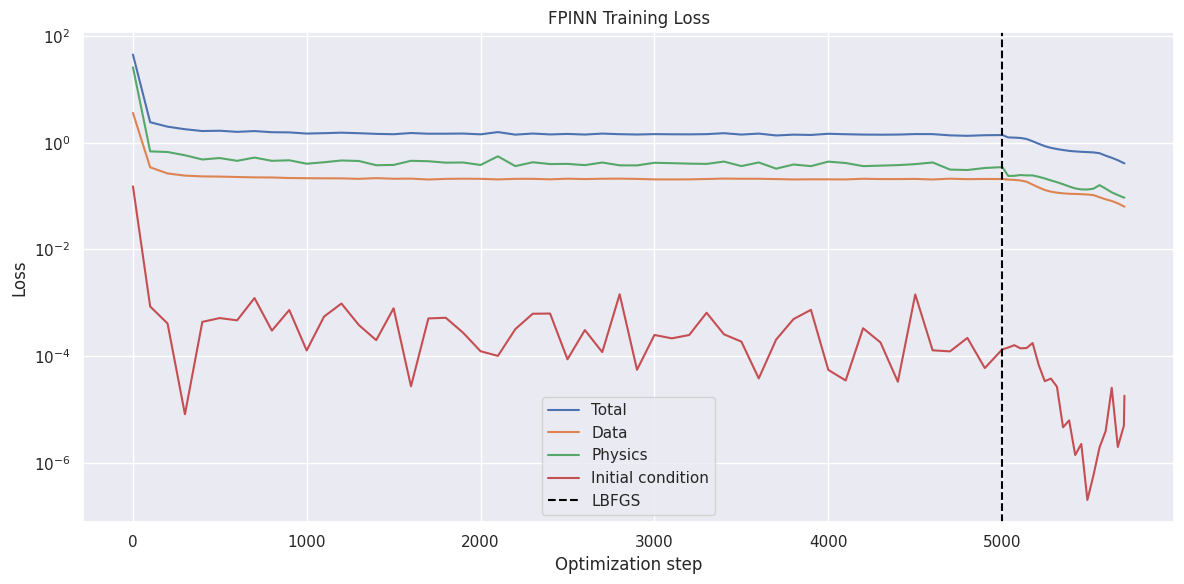

In [57]:
steps = np.array(history["step"])
plt.figure(figsize=(12, 6))
plt.semilogy(steps, history["total"], label="Total")
plt.semilogy(steps, history["data"], label="Data")
plt.semilogy(steps, history["physics"], label="Physics")
plt.semilogy(steps, history["ic"], label="Initial condition")
plt.axvline(x=ADAMW_EPOCHS, color='black', linestyle='--', label="LBFGS")

plt.xlabel("Optimization step")
plt.ylabel("Loss")
plt.title("FPINN Training Loss")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 14. Evolution of Parameters $\sigma$, $\rho$, and $\beta$

This section visualizes inverse parameter estimation during training.

Each subplot shows the estimated parameter and a horizontal line indicating its reference value. If inverse learning works well, the parameter trajectory should move from the initial guess toward the reference value:

$$
\sigma_{true}=10,
\qquad
\rho_{true}=28,
\qquad
\beta_{true}=\frac{8}{3}.
$$

The vertical line marks the start of the L-BFGS stage, allowing changes caused by the second optimizer to be observed separately.

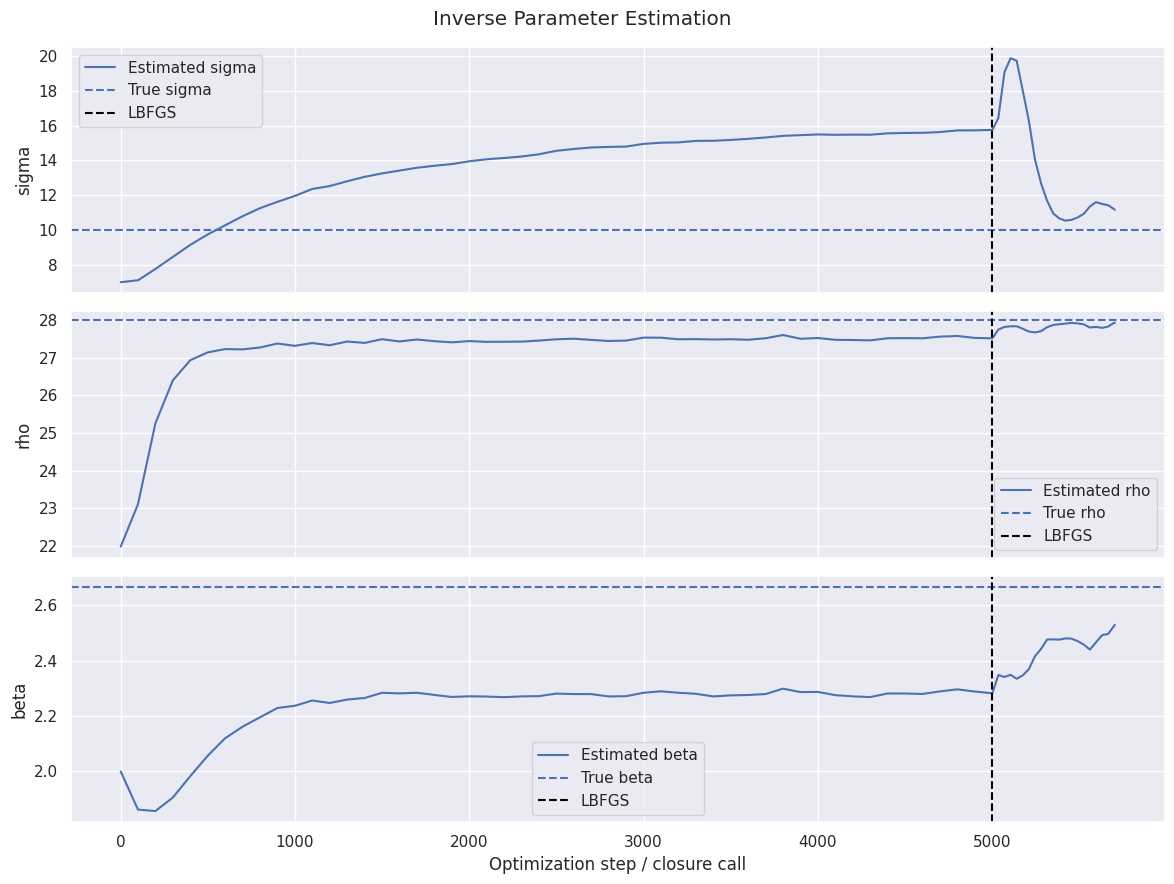

In [58]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, key, true_val in zip(
    axes,
    ["sigma", "rho", "beta"],
    [SIGMA_TRUE, RHO_TRUE, BETA_TRUE],
):
    ax.plot(steps, history[key], label=f"Estimated {key}")
    ax.axhline(true_val, linestyle="--", label=f"True {key}")
    ax.axvline(x=ADAMW_EPOCHS, color='black', linestyle='--', label="LBFGS")
    ax.set_ylabel(key)
    ax.grid(True)
    ax.legend()
axes[-1].set_xlabel("Optimization step / closure call")
fig.suptitle("Inverse Parameter Estimation")
plt.tight_layout()
plt.show()

## 15. Evolution of the Global Skip $\lambda$

The coefficient $\lambda$ controls the contribution of the initial representation `x_input`, which is added back after all residual blocks:

$$
\mathbf{x}_{global}
=
\mathbf{x}_{res}+\lambda\mathbf{x}_{input}.
$$

Because $\lambda$ is trainable, the model can adjust how much information from the initial representation is retained through the final stage of the network.

Dalam implementasi ini, $\lambda$ selalu dibatasi pada:

$$
0.05\leq\lambda\leq0.5.
$$

The following plot shows how its value changes during AdamW and L-BFGS.

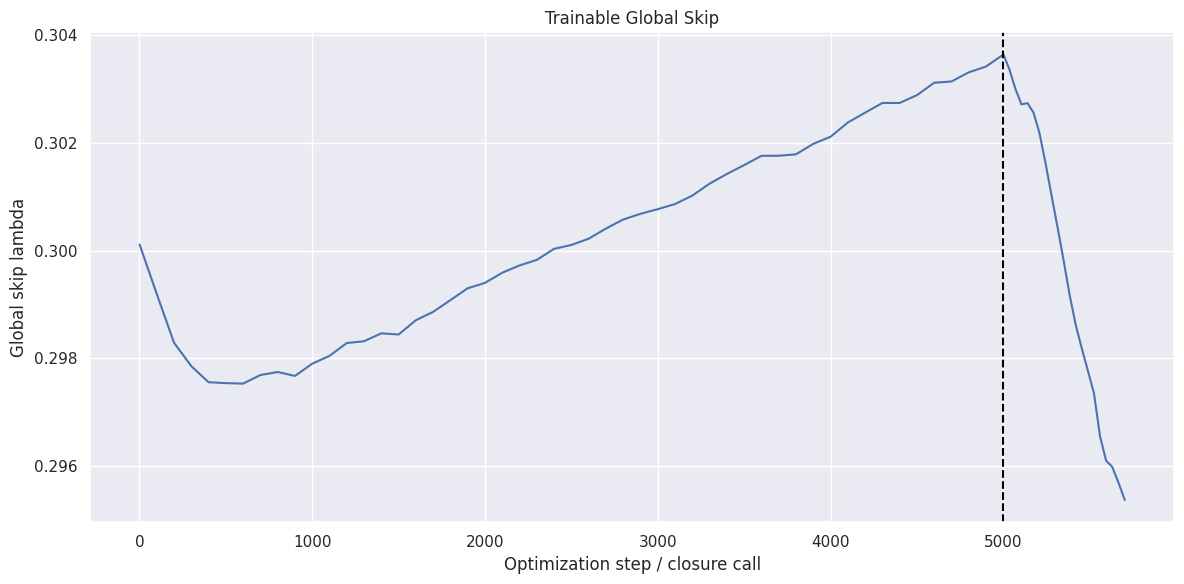

In [59]:
plt.figure(figsize=(12, 6))
plt.plot(steps, history["lambda"])
plt.xlabel("Optimization step / closure call")
plt.ylabel("Global skip lambda")
plt.title("Trainable Global Skip")
plt.axvline(x=ADAMW_EPOCHS, color='black', linestyle='--', label="LBFGS")
plt.grid(True)
plt.tight_layout()
plt.show()

## 16. Evolution of the Mean Gate in Each Residual Block

Each residual block has a gate vector with one gate value for each hidden feature. For easier diagnosis, these values are averaged for each block:

$$
\bar{g}^{(k)}
=
\frac{1}{H}\sum_{j=1}^{H}g_j^{(k)},
$$

where $H=128$ is the hidden dimension and $k$ is the block index.

Gate dibatasi pada interval $[0.1,0.9]$. The mean gate value indicates the average strength of the residual branch:

- nilai yang lebih kecil berarti kontribusi residual branch lebih ditekan;
- nilai yang lebih besar berarti residual branch diberi kontribusi lebih kuat;
- mean yang mendekati batas secara terus-menerus dapat menunjukkan bahwa gate terdorong menuju salah satu ujung interval.

The mean gate does not describe the full distribution of gates across neurons, but it is useful as a concise diagnostic.

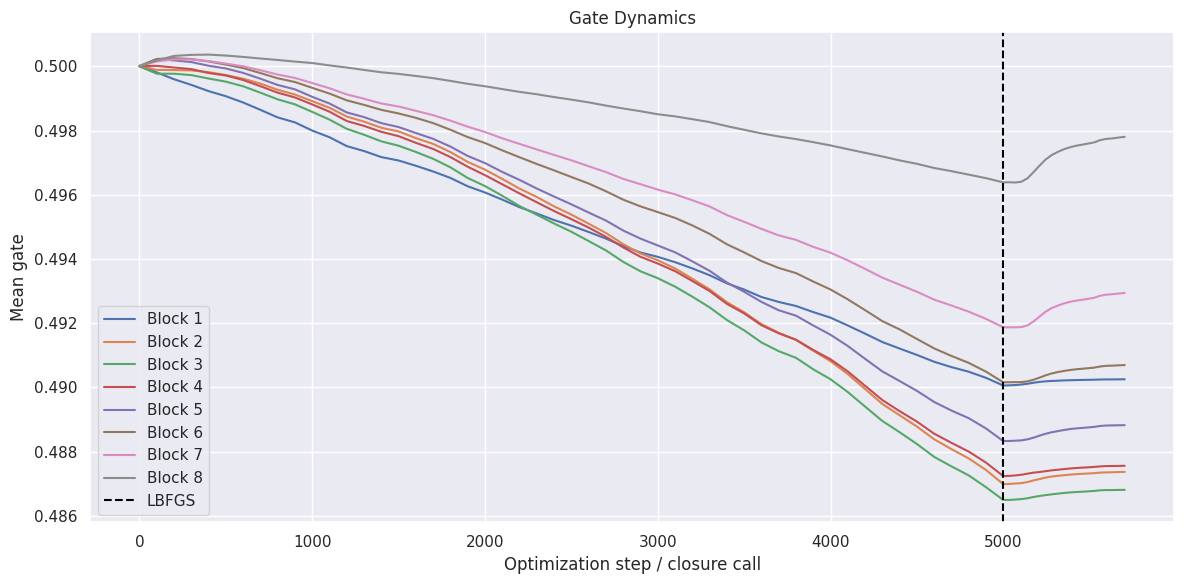

In [61]:
gate_hist = np.array(history["gate_means"])
plt.figure(figsize=(12, 6))
for i in range(gate_hist.shape[1]):
    plt.plot(steps, gate_hist[:, i], label=f"Block {i+1}")
plt.xlabel("Optimization step / closure call")
plt.ylabel("Mean gate")
plt.title("Gate Dynamics")
plt.axvline(x=ADAMW_EPOCHS, color='black', linestyle='--', label="LBFGS")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 17. Ground Truth vs. FPINN Predictions

All three FPINN-predicted states are directly compared with the ground-truth trajectory over the entire time interval.

The plot also shows the locations of training observations. Note that the markers use ground-truth values at `train_idx`, whereas training used values with added noise and `clamp_min(0.0)`.

For the Lorenz system, agreement may look good over the initial horizon but later exhibit phase divergence. This should be analyzed alongside parameter estimates and physics residuals.

Time grid: 1000
Predictions: 1000 1000 1000


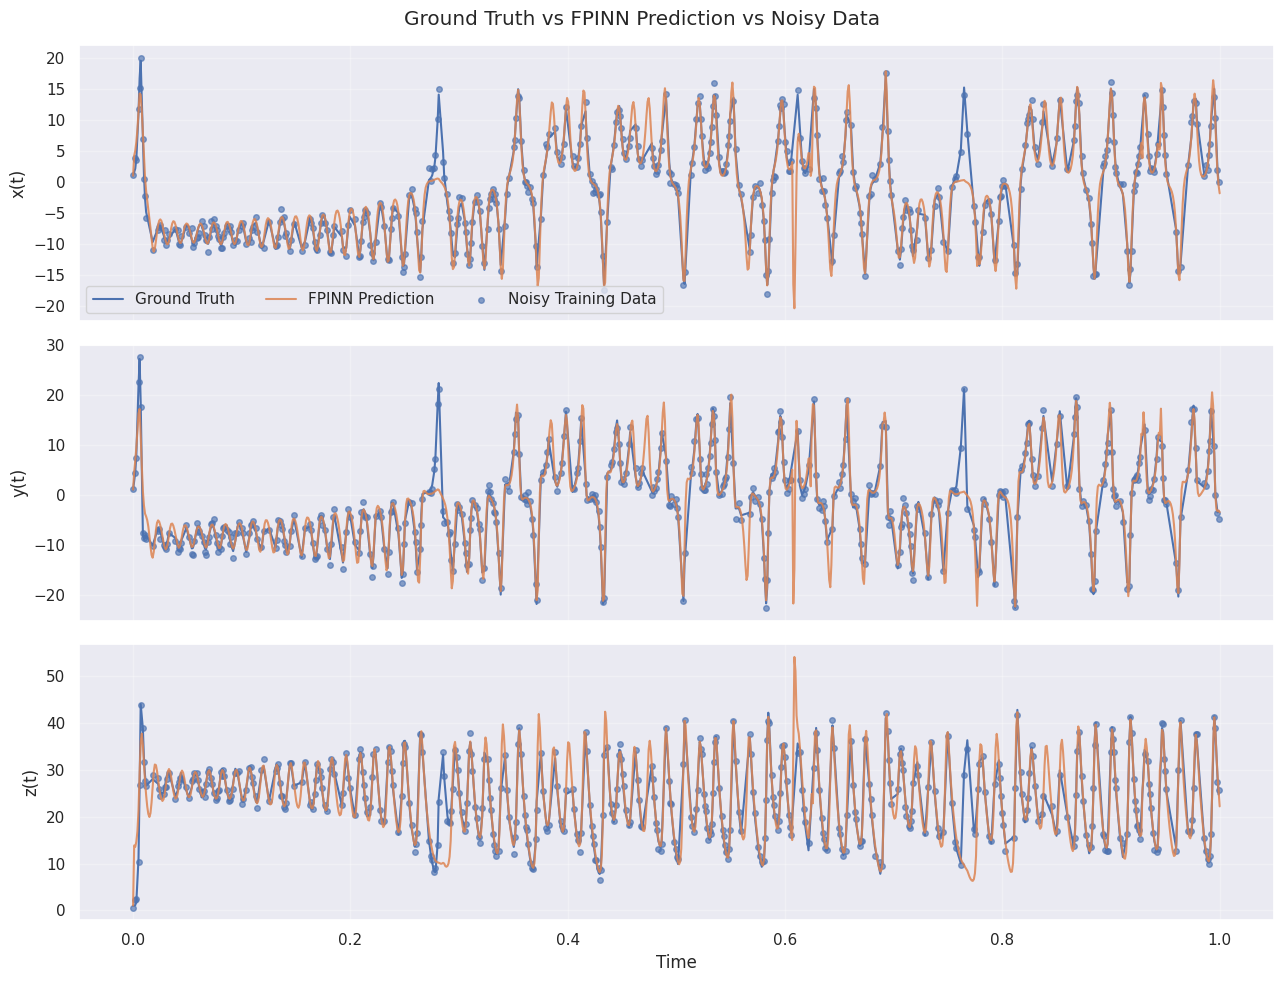

In [65]:
# Generate predictions on all 1000 time points
model.eval()
with torch.no_grad():
    X_pred_t, Y_pred_t, Z_pred_t, sigma_est, rho_est, beta_est = model(t_all)

def to_np(x):
    return x.detach().cpu().numpy().ravel()

t_all_np = to_np(t_all)
t_train_np = to_np(t_train)

X_pred = to_np(X_pred_t)
Y_pred = to_np(Y_pred_t)
Z_pred = to_np(Z_pred_t)

X_train_np = to_np(X_train)
Y_train_np = to_np(Y_train)
Z_train_np = to_np(Z_train)

X_noisy = to_np(X_train_noisy)
Y_noisy = to_np(Y_train_noisy)
Z_noisy = to_np(Z_train_noisy)

print("Time grid:", len(t_all_np))
print("Predictions:", len(X_pred), len(Y_pred), len(Z_pred))

# Plot comparisons
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

for ax, truth, pred, noisy, label in zip(
    axes,
    [X_train_np, Y_train_np, Z_train_np],
    [X_pred, Y_pred, Z_pred],
    [X_noisy, Y_noisy, Z_noisy],
    ["x(t)", "y(t)", "z(t)"]
):
    ax.plot(
        t_train_np, truth,
        label="Ground Truth",
        linewidth=1.5
    )

    ax.plot(
        t_all_np, pred,
        label="FPINN Prediction",
        linewidth=1.5,
        alpha=0.85
    )

    ax.scatter(
        t_train_np, noisy,
        label="Noisy Training Data",
        s=16,
        alpha=0.65
    )

    ax.set_ylabel(label)
    ax.grid(True, alpha=0.3)

axes[0].legend(ncol=3)
axes[-1].set_xlabel("Time")
fig.suptitle("Ground Truth vs FPINN Prediction vs Noisy Data")
plt.tight_layout()
plt.show()


## 18. Absolute Error over Time

Absolute error is calculated for each state:

$$
e_x(t)=|\hat{x}(t)-x(t)|,
$$

$$
e_y(t)=|\hat{y}(t)-y(t)|,
$$

$$
e_z(t)=|\hat{z}(t)-z(t)|.
$$

The $y$-axis uses a logarithmic scale so that both small and large errors can be viewed in the same plot.

This plot helps identify when predictions begin to diverge from the ground truth. In chaotic dynamics, error can grow over time even when the physical parameters and differential residuals are reasonably close.

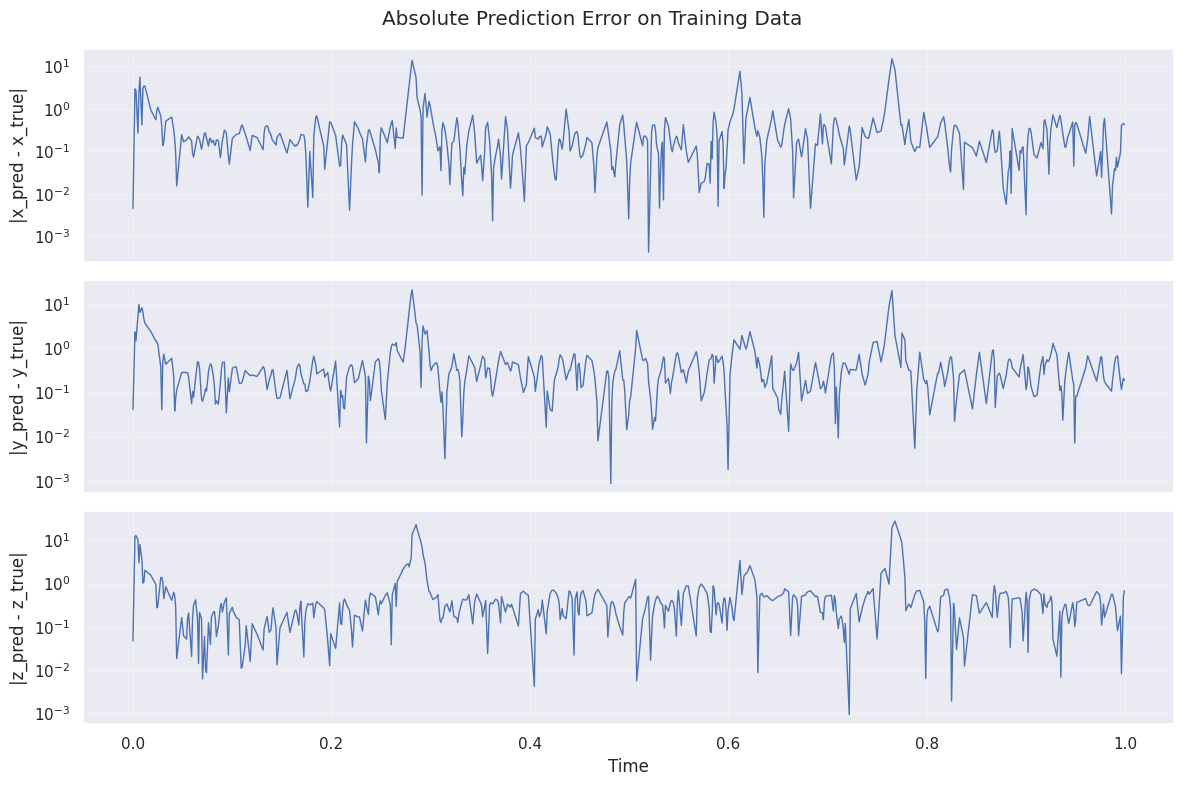

In [66]:
# Convert tensors to NumPy arrays
def to_np(x):
    return x.detach().cpu().numpy().ravel() if hasattr(x, "detach") else np.asarray(x).ravel()

t_train_np = to_np(t_train)

X_true_np = to_np(X_train)
Y_true_np = to_np(Y_train)
Z_true_np = to_np(Z_train)

X_noisy_np = to_np(X_train_noisy)
Y_noisy_np = to_np(Y_train_noisy)
Z_noisy_np = to_np(Z_train_noisy)

# Predict at training time points
model.eval()
with torch.no_grad():
    X_fit_t, Y_fit_t, Z_fit_t, *_ = model(t_train)

X_fit = to_np(X_fit_t)
Y_fit = to_np(Y_fit_t)
Z_fit = to_np(Z_fit_t)

# Absolute errors against clean training reference
errors = [
    np.abs(X_fit - X_true_np),
    np.abs(Y_fit - Y_true_np),
    np.abs(Z_fit - Z_true_np)
]

labels = [
    "|x_pred - x_true|",
    "|y_pred - y_true|",
    "|z_pred - z_true|"
]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

for ax, error, label in zip(axes, errors, labels):
    ax.plot(t_train_np, np.maximum(error, 1e-12), linewidth=1.0)
    ax.set_ylabel(label)
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
fig.suptitle("Absolute Prediction Error on Training Data")
plt.tight_layout()
plt.show()


## 19. 3D Lorenz Attractor — Ground Truth vs. FPINN

In addition to comparing states over time, the trajectory structure can be examined in the three-dimensional phase space $(x,y,z)$.

The ground-truth and FPINN-predicted curves are plotted in the same coordinate system. This visualization helps determine whether the network has learned the general geometry of the Lorenz attractor, even if pointwise positions over time begin to differ over a long horizon.

A matching attractor shape does not automatically mean the temporal trajectories are identical, so this result should be considered alongside the state plots, absolute errors, parameter estimates, and physics residuals.

Ground truth: 500 500 500
FPINN: 1000 1000 1000


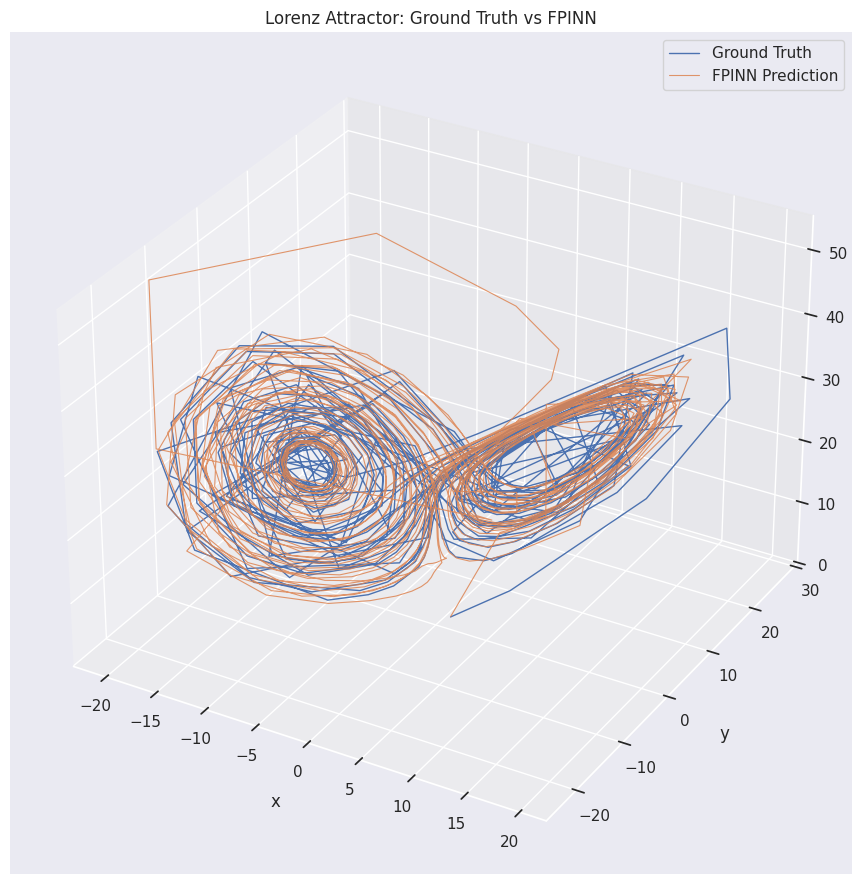

In [67]:
# Ground truth at training points
X_true = to_np(X_train)
Y_true = to_np(Y_train)
Z_true = to_np(Z_train)

# Generate FPINN predictions at all time points
model.eval()
with torch.no_grad():
    X_pred_t, Y_pred_t, Z_pred_t, sigma_est, rho_est, beta_est = model(t_all)

X_pred = to_np(X_pred_t)
Y_pred = to_np(Y_pred_t)
Z_pred = to_np(Z_pred_t)

# Verify dimensions
print("Ground truth:", len(X_true), len(Y_true), len(Z_true))
print("FPINN:", len(X_pred), len(Y_pred), len(Z_pred))

# Plot 3D Lorenz attractor
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    X_true, Y_true, Z_true,
    linewidth=1.0,
    label="Ground Truth"
)

ax.plot(
    X_pred, Y_pred, Z_pred,
    linewidth=0.8,
    alpha=0.85,
    label="FPINN Prediction"
)

ax.set_xlabel("x", labelpad=10)
ax.set_ylabel("y", labelpad=10)
ax.set_zlabel("z", labelpad=10)
ax.set_title("Lorenz Attractor: Ground Truth vs FPINN")
ax.legend()
plt.tight_layout()
plt.show()


## 20. Physics Residuals over the Entire Domain

After training, physics residuals are evaluated across the entire normalized time grid.

Residual yang digunakan adalah:

$$
f_x
=
\frac{d\hat{x}}{dt}-\sigma(\hat{y}-\hat{x}),
$$

$$
f_y
=
\frac{d\hat{y}}{dt}-\left[\hat{x}(\rho-\hat{z})-\hat{y}\right],
$$

$$
f_z
=
\frac{d\hat{z}}{dt}-\left(\hat{x}\hat{y}-\beta\hat{z}\right).
$$

If the network output exactly satisfies the Lorenz equations, all three residuals are zero.

In addition to plotting residuals over time, the code calculates residual RMSE:

$$
\operatorname{RMSE}(f)
=
\sqrt{\frac{1}{N}\sum_{i=1}^{N}f_i^2}.
$$

Small residuals indicate local consistency with the differential equations. In a chaotic system, small residuals do not always produce identical pointwise trajectories over a long horizon because small errors can accumulate.

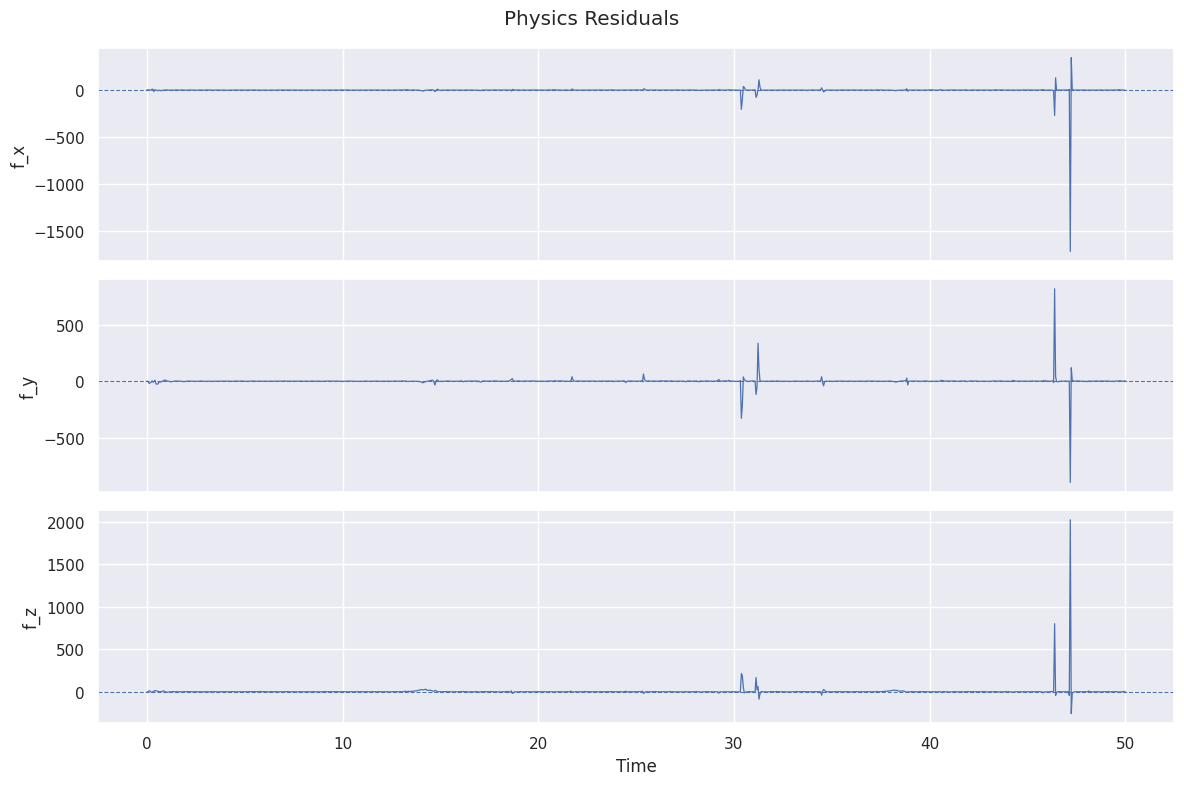

Residual RMSE:
f_x: 56.806213
f_y: 42.403645
f_z: 70.200905


In [68]:
model.eval()
fX, fY, fZ = physics_residuals(model, t_all)
fX = fX.detach().cpu().numpy().ravel()
fY = fY.detach().cpu().numpy().ravel()
fZ = fZ.detach().cpu().numpy().ravel()

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, residual, label in zip(axes, [fX, fY, fZ], ["f_x", "f_y", "f_z"]):
    ax.plot(time, residual, linewidth=0.9)
    ax.axhline(0.0, linestyle="--", linewidth=0.8)
    ax.set_ylabel(label)
    ax.grid(True)
axes[-1].set_xlabel("Time")
fig.suptitle("Physics Residuals")
plt.tight_layout()
plt.show()

print("Residual RMSE:")
print("f_x:", np.sqrt(np.mean(fX**2)))
print("f_y:", np.sqrt(np.mean(fY**2)))
print("f_z:", np.sqrt(np.mean(fZ**2)))

## 21. Final Diagnostic Summary

This section displays the final values of:

- estimasi $\sigma$, $\rho$, dan $\beta$;
- trainable global skip $\lambda$;
- mean gate untuk setiap `GatedResBlock`.

The estimated parameters are directly compared with the reference parameters. Mean gate values help show whether a residual block tends to make a low, moderate, or near-upper-bound contribution through its residual branch.

In the current code version, `gate_diagnostics` returns only `gate_means`, so the final summary does not display residual scale.

In [48]:
gate_means, gate_mins, gate_maxs = gate_diagnostics(model, t_probe)

for i, (mean_g, min_g, max_g) in enumerate(
    zip(gate_means, gate_mins, gate_maxs), start=1
):
    print(
        f"Block {i}: "
        f"mean={mean_g:.6f}, "
        f"min={min_g:.6f}, "
        f"max={max_g:.6f}"
    )

Block 1: mean=0.490253, min=0.472812, max=0.505393
Block 2: mean=0.487367, min=0.464486, max=0.506310
Block 3: mean=0.486808, min=0.469842, max=0.506255
Block 4: mean=0.487558, min=0.465107, max=0.505998
Block 5: mean=0.488824, min=0.460636, max=0.502413
Block 6: mean=0.490696, min=0.473612, max=0.506931
Block 7: mean=0.492943, min=0.467098, max=0.512272
Block 8: mean=0.497805, min=0.474096, max=0.532534


## 22. Interpretation Notes

Inverse FPINN results should be interpreted using several indicators together.

### Parameter Estimation

Values of $\hat{\sigma}$, $\hat{\rho}$, and $\hat{\beta}$ close to the reference parameters indicate that the model has identified the physical dynamics used to generate the data.

### Data Loss

$\mathcal{L}_{data}$ measures fit to the **noisy training observations** after preprocessing. A small value means the model predictions are close to the data actually used for training.

### Physics Loss

$\mathcal{L}_{physics}$ measures violations of the Lorenz equations at collocation points. A small value indicates that the network output is more consistent with the governing equations.

### Initial-Condition Loss

$\mathcal{L}_{IC}$ keeps the prediction at $t=0$ close to the initial condition $(1,1,1)$.

### Gates

The mean gate for each block indicates the average contribution of its residual branch. Since gates are constrained to $[0.1,0.9]$, values that remain close to either bound may indicate a tendency to suppress or strengthen the residual transformation.

### Global Skip

Nilai $\lambda$ menunjukkan kontribusi representasi awal yang dilewatkan langsung ke bagian akhir backbone. Karena dibatasi pada $[0.05,0.5]$, global skip tidak dapat sepenuhnya hilang atau mendominasi representation.

### Trajectory pada sistem chaotic

Sistem Lorenz sangat sensitif terhadap perturbasi. Karena itu, RMSE trajectory pada seluruh horizon tidak sebaiknya digunakan sebagai satu-satunya indikator kualitas inverse model. Evaluasi parameter, physics residual, bentuk attractor, dan pola error terhadap waktu memberi informasi tambahan.

### Parameter yang dapat dituning

Jika training belum stabil, beberapa komponen yang dapat diperiksa adalah:

- `W_DATA`, `W_PHYS`, dan `W_IC`;
- learning rate AdamW;
- jumlah dan sampling collocation points;
- jumlah epoch AdamW;
- jumlah iterasi L-BFGS;
- jumlah Fourier frequencies;
- hidden dimension dan jumlah residual block;
- batas gate dan global skip.
